<h1 align="center">Hugging Face: SPAM Classification using BERT</h1>

## 1. Install the libraries

In [ ]:
%pip install transformers datasets scikit-learn pandas matplotlib

## 2. Import the libraries

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from transformers import BertTokenizer, BertModel
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fix the random starting points, so results are repeatable
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42);

In [ ]:
# Use the computer's GPU if it has one, otherwise the CPU:
#   - NVIDIA graphics card → "cuda"
#   - Apple Silicon Mac    → "mps"
#   - no supported GPU     → "cpu"

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
device

## 3. Credits

**SMS Spam Collection** by Tiago A. Almeida and José María Gómez Hidalgo

Original source: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) · License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

**BERT (bert-base-uncased)** by Google

Original source: [Hugging Face Model Hub](https://huggingface.co/google-bert/bert-base-uncased) · License: [Apache 2.0](https://www.apache.org/licenses/LICENSE-2.0)

Many thanks to the creators of the dataset and to Google for making them publicly available.

## 4. Load the dataset

The same dataset is also available on [Hugging Face Datasets](https://huggingface.co/datasets/ucirvine/sms_spam). The data is loaded from there (`ucirvine/sms_spam`) and converted into a pandas DataFrame.

In [53]:
dataset = load_dataset("ucirvine/sms_spam")
df = dataset["train"].to_pandas()
df.head()

,sms,label
0,"Go until jurong point, crazy.. Available only ...",0
1,Ok lar... Joking wif u oni...\n,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives aro...",0


## 5. Explore the dataset

### 5.1 Dataset overview

In [6]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (5574, 2)
Columns: ['sms', 'label']


In [7]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
sms      0
label    0
dtype: int64


In [8]:
print("\nHam (0) and spam (1) counts:")
print(df["label"].value_counts())


Ham (0) and spam (1) counts:
label
0    4827
1     747
Name: count, dtype: int64


In [9]:
print("\nShare of each label (%):")
print((df["label"].value_counts(normalize=True) * 100).round(2))


Share of each label (%):
label
0    86.6
1    13.4
Name: proportion, dtype: float64


### 5.2 Check for duplicate messages

In [10]:
duplicates = df.duplicated(subset="sms").sum()
print("Duplicate messages:", duplicates)

Duplicate messages: 403


### 5.3 Remove duplicate messages

In [11]:
df = df.drop_duplicates(subset="sms").reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print((df["label"].value_counts(normalize=True) * 100).map("{:.2f}%".format))

Shape after removing duplicates: (5171, 2)
label
0    87.37%
1    12.63%
Name: proportion, dtype: str


### 5.4 Message length

        count  mean   std  min   25%   50%   75%    max
label                                                  
0      4518.0  14.2  11.2  1.0   7.0  11.0  19.0  171.0
1       653.0  23.7   5.9  2.0  22.0  25.0  28.0   35.0


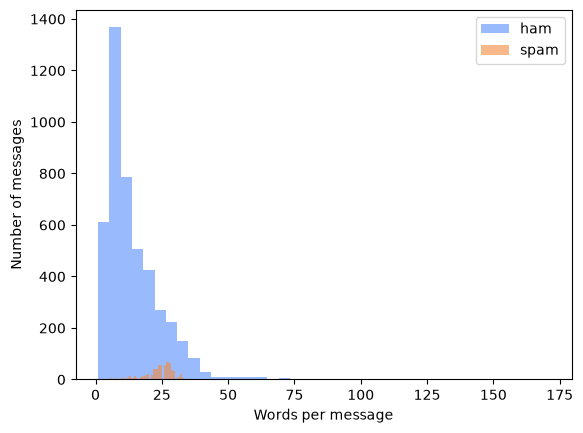

In [12]:
df["num_words"] = df["sms"].str.split().str.len()
print(df.groupby("label")["num_words"].describe().round(1))

df[df["label"] == 0]["num_words"].plot(kind="hist", bins=40, alpha=0.6, label="ham")
df[df["label"] == 1]["num_words"].plot(kind="hist", bins=40, alpha=0.6, label="spam")
plt.xlabel("Words per message")
plt.ylabel("Number of messages")
plt.legend()
plt.show()

## 6. Split the data into training, validation and test sets

In [13]:
from sklearn.model_selection import train_test_split

# Step 1: keep 70% for training, set aside 30%
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)

# Step 2: split the 30% in half → 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42
)

for name, part in [("Training", train_df), ("Validation", val_df), ("Test", test_df)]:
    spam_share = part["label"].mean() * 100
    print(f"{name:10s}: {len(part):5d} messages | spam: {spam_share:.2f}%")

Training  :  3619 messages | spam: 12.63%
Validation:   776 messages | spam: 12.63%
Test      :   776 messages | spam: 12.63%


## 7. Tokenization

### 7.1 Load BERT's tokenizer

In [14]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
print("Vocabulary size:", tokenizer.vocab_size)

Vocabulary size: 30522


### 7.2 Tokenization function

In [15]:
MAX_LENGTH = 128

def tokenize_function(texts, labels):
    encodings = tokenizer(
        texts,
        padding="max_length",    # fill shorter messages with [PAD] up to 128 tokens
        max_length=MAX_LENGTH,
        truncation=True,         # cut longer messages at 128 tokens
        return_tensors="pt"      # return PyTorch tensors
    )
    return encodings["input_ids"], encodings["attention_mask"], torch.tensor(labels, dtype=torch.float)

### 7.3 Test the function on two example messages

In [16]:
ids, mask, labels = tokenize_function(["Hurry up, click here", "I will see you tomorrow"], [1, 0])

print("input_ids shape:     ", tuple(ids.shape))
print("attention_mask shape:", tuple(mask.shape))
print("labels:              ", labels.tolist(), "\n")

for i in range(2):
    n = int(mask[i].sum())    # number of real (non-padding) tokens
    print("Tokens:", tokenizer.convert_ids_to_tokens(ids[i][:n].tolist()))
    print("IDs:   ", ids[i][:n].tolist())
    print(f"Real tokens: {n} | Padding: {MAX_LENGTH - n}\n")

input_ids shape:      (2, 128)
attention_mask shape: (2, 128)
labels:               [1.0, 0.0] 

Tokens: ['[CLS]', 'hurry', 'up', ',', 'click', 'here', '[SEP]']
IDs:    [101, 9241, 2039, 1010, 11562, 2182, 102]
Real tokens: 7 | Padding: 121

Tokens: ['[CLS]', 'i', 'will', 'see', 'you', 'tomorrow', '[SEP]']
IDs:    [101, 1045, 2097, 2156, 2017, 4826, 102]
Real tokens: 7 | Padding: 121



### 7.4 How many messages are longer than 128 tokens?

In [17]:
# +2 for [CLS] and [SEP]
token_lengths = df["sms"].apply(lambda text: len(tokenizer.tokenize(text)) + 2)

print(token_lengths.describe().round(1))
too_long = (token_lengths > MAX_LENGTH).sum()
print(f"\nMessages longer than {MAX_LENGTH} tokens: {too_long} ({too_long / len(df) * 100:.2f}%)")

count    5171.0
mean       25.0
std        17.0
min         3.0
25%        12.0
50%        19.0
75%        35.0
max       238.0
Name: sms, dtype: float64

Messages longer than 128 tokens: 7 (0.14%)


In [18]:
print(df.loc[token_lengths > MAX_LENGTH, "label"].value_counts())

label
0    7
Name: count, dtype: int64


### 7.5 Tokenize the training, validation and test sets

In [19]:
train_ids, train_mask, train_labels = tokenize_function(train_df["sms"].tolist(), train_df["label"].tolist())
val_ids,   val_mask,   val_labels   = tokenize_function(val_df["sms"].tolist(),   val_df["label"].tolist())
test_ids,  test_mask,  test_labels  = tokenize_function(test_df["sms"].tolist(),  test_df["label"].tolist())

print("Training:  ", tuple(train_ids.shape))
print("Validation:", tuple(val_ids.shape))
print("Test:      ", tuple(test_ids.shape))

Training:   (3619, 128)
Validation: (776, 128)
Test:       (776, 128)


## 8. Define the model

In [20]:
class SpamClassifier(nn.Module):
    def __init__(self, freeze_bert=False):
        super().__init__()
        self.bert = BertModel.from_pretrained("bert-base-uncased")

        if freeze_bert:                          # optional: keep BERT's weights fixed
            for param in self.bert.parameters():
                param.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Linear(self.bert.config.hidden_size, 256),   # 768 → 256
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)                                # 256 → 1 raw score (no Sigmoid here)
        )

    def forward(self, input_ids, attention_mask):
        bert_output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_vector = bert_output.last_hidden_state[:, 0, :]  # [CLS] token: (batch, 768)
        return self.classifier(cls_vector).squeeze(-1)       # (batch,): one score per message

### 8.1 Create the model, optimizer and loss function

In [21]:
FREEZE_BERT = False    # True = train only the classifier (fast); False = fine-tune all of BERT

model = SpamClassifier(freeze_bert=FREEZE_BERT).to(device)

optimizer = optim.AdamW([
    {"params": model.bert.parameters(),       "lr": 2e-5},   # small steps for pre-trained BERT
    {"params": model.classifier.parameters(), "lr": 1e-3},   # bigger steps for the new classifier
], weight_decay=0.01)

criterion = nn.BCEWithLogitsLoss()   # sigmoid + binary cross-entropy, combined and stable

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total parameters:     109,679,361
Trainable parameters: 109,679,361


## 9. Create datasets and data loaders

### 9.1 Bundle the inputs, masks and labels

In [22]:
train_dataset = torch.utils.data.TensorDataset(train_ids, train_mask, train_labels)
val_dataset   = torch.utils.data.TensorDataset(val_ids,   val_mask,   val_labels)
test_dataset  = torch.utils.data.TensorDataset(test_ids,  test_mask,  test_labels)

print("Training examples:  ", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:      ", len(test_dataset))

Training examples:   3619
Validation examples: 776
Test examples:       776


### 9.2 Create the data loaders (batches)

In [23]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print("Training batches:  ", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:      ", len(test_loader))

Training batches:   57
Validation batches: 13
Test batches:       13


## 10. Train the model

In [24]:
import time

EPOCHS = 3
best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

for epoch in range(EPOCHS):
    start = time.time()

    # ---------- Training ----------
    model.train()                                   # dropout ON
    total_train_loss = 0

    for batch, (input_ids, attention_mask, labels) in enumerate(train_loader):
        input_ids      = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels         = labels.to(device)

        optimizer.zero_grad()                       # 1. clear old gradients
        outputs = model(input_ids, attention_mask)  # 2. predict
        loss = criterion(outputs, labels)           # 3. measure the mistakes
        loss.backward()                             # 4. backpropagation
        optimizer.step()                            # 5. update the weights

        total_train_loss += loss.item()
        if batch % 10 == 0:
            print(f"Epoch {epoch + 1} | batch {batch}/{len(train_loader)} | loss {loss.item():.4f}")

    avg_train_loss = total_train_loss / len(train_loader)

    # ---------- Validation ----------
    model.eval()                                    # dropout OFF
    total_val_loss, correct = 0, 0

    with torch.no_grad():                           # only checking, no learning
        for input_ids, attention_mask, labels in val_loader:
            input_ids      = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels         = labels.to(device)

            outputs = model(input_ids, attention_mask)
            total_val_loss += criterion(outputs, labels).item()
            predictions = (outputs > 0).float()     # score > 0 means probability > 50% → spam
            correct += (predictions == labels).sum().item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_accuracy = correct / len(val_dataset)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch + 1}/{EPOCHS} | training loss {avg_train_loss:.4f} | "
          f"validation loss {avg_val_loss:.4f} | validation accuracy {val_accuracy:.2%} | "
          f"{time.time() - start:.0f} seconds")

    # ---------- Keep the best version ----------
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "best_spam_bert.pt")
        print("✓ Best model so far, saved to best_spam_bert.pt\n")
    else:
        print("✗ Validation loss did not improve\n")

Epoch 1 | batch 0/57 | loss 0.6242
Epoch 1 | batch 10/57 | loss 0.1367
Epoch 1 | batch 20/57 | loss 0.0105
Epoch 1 | batch 30/57 | loss 0.0750
Epoch 1 | batch 40/57 | loss 0.0073
Epoch 1 | batch 50/57 | loss 0.0116

Epoch 1/3 | training loss 0.1030 | validation loss 0.0386 | validation accuracy 98.84% | 103 seconds
✓ Best model so far, saved to best_spam_bert.pt

Epoch 2 | batch 0/57 | loss 0.0026
Epoch 2 | batch 10/57 | loss 0.0204
Epoch 2 | batch 20/57 | loss 0.0023
Epoch 2 | batch 30/57 | loss 0.0531
Epoch 2 | batch 40/57 | loss 0.0737
Epoch 2 | batch 50/57 | loss 0.0181

Epoch 2/3 | training loss 0.0204 | validation loss 0.0423 | validation accuracy 99.10% | 107 seconds
✗ Validation loss did not improve

Epoch 3 | batch 0/57 | loss 0.0056
Epoch 3 | batch 10/57 | loss 0.0086
Epoch 3 | batch 20/57 | loss 0.0005
Epoch 3 | batch 30/57 | loss 0.0007
Epoch 3 | batch 40/57 | loss 0.0005
Epoch 3 | batch 50/57 | loss 0.0002

Epoch 3/3 | training loss 0.0061 | validation loss 0.0479 | valida

## 11. Evaluate the model

### 11.1 Load the best model (epoch 1)

In [25]:
model.load_state_dict(torch.load("best_spam_bert.pt", map_location=device))
model.eval()
print("Best model loaded")

Best model loaded


### 11.2 A helper to get the model's predictions

In [26]:
def get_predictions(loader):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():                                   # only checking, no learning
        for input_ids, attention_mask, labels in loader:
            scores = model(input_ids.to(device), attention_mask.to(device))
            all_probs.append(torch.sigmoid(scores).cpu())   # score → spam probability
            all_labels.append(labels)
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    preds  = (probs > 0.5).astype(int)                      # above 50% → spam (1)
    return labels, preds, probs

### 11.3 Training, validation and test accuracy

In [27]:
for name, loader in [("Training", train_loader), ("Validation", val_loader), ("Test", test_loader)]:
    y_true, y_pred, _ = get_predictions(loader)
    accuracy = (y_true == y_pred).mean()
    wrong = (y_true != y_pred).sum()
    print(f"{name:10s} accuracy: {accuracy:.2%}  ({wrong} wrong out of {len(y_true)})")

Training   accuracy: 99.64%  (13 wrong out of 3619)
Validation accuracy: 98.84%  (9 wrong out of 776)
Test       accuracy: 99.36%  (5 wrong out of 776)


### 11.4 Test set: classification report and confusion matrix

              precision    recall  f1-score   support

         ham     0.9927    1.0000    0.9963       678
        spam     1.0000    0.9490    0.9738        98

    accuracy                         0.9936       776
   macro avg     0.9963    0.9745    0.9851       776
weighted avg     0.9936    0.9936    0.9935       776



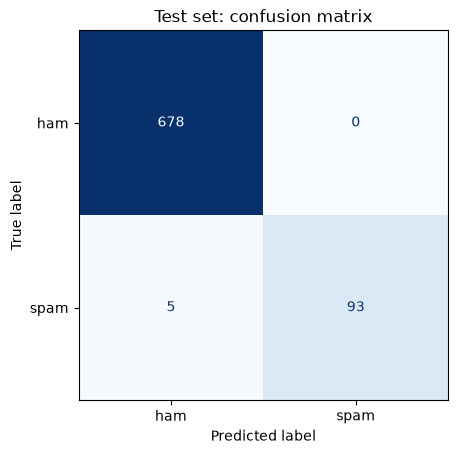

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred, y_prob = get_predictions(test_loader)

print(classification_report(y_true, y_pred, target_names=["ham", "spam"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=["ham", "spam"]).plot(cmap="Blues", colorbar=False)
plt.title("Test set: confusion matrix")
plt.show()

## 12. Try the model on new messages

In [29]:
def predict(model, text, max_length=MAX_LENGTH):
    encoding = tokenizer(
        text,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )
    input_ids      = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    model.eval()
    with torch.no_grad():
        score = model(input_ids, attention_mask)      # raw score
        probability = torch.sigmoid(score).item()     # score → spam probability

    label = "spam" if probability > 0.5 else "ham"
    print(f"{label:4s} | spam probability: {probability:6.1%} | {text}")

In [30]:
predict(model, "This is your last chance to WIN the CASH. Please click the link.")
predict(model, "Dear Vamshi, I hope to see you on Sunday.")
predict(model, "I won the office quiz competition yesterday, the prize was a free dinner haha.")

spam | spam probability:  83.5% | This is your last chance to WIN the CASH. Please click the link.
ham  | spam probability:   0.1% | Dear Vamshi, I hope to see you on Sunday.
ham  | spam probability:   1.4% | I won the office quiz competition yesterday, the prize was a free dinner haha.


## 13. Look inside BERT: following one message step by step

### 13.1 From text to tokens and IDs

In [40]:
example = "This is your last chance to WIN the CASH. Please click the link."

model.eval()
enc = tokenizer(example, return_tensors="pt")        # no padding here: only the real tokens
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])

print("Number of tokens:", len(tokens), "\n")
for pos, (token, token_id) in enumerate(zip(tokens, enc["input_ids"][0].tolist())):
    print(f"position {pos:2d} | {token:10s} | ID {token_id}")

Number of tokens: 17 

position  0 | [CLS]      | ID 101
position  1 | this       | ID 2023
position  2 | is         | ID 2003
position  3 | your       | ID 2115
position  4 | last       | ID 2197
position  5 | chance     | ID 3382
position  6 | to         | ID 2000
position  7 | win        | ID 2663
position  8 | the        | ID 1996
position  9 | cash       | ID 5356
position 10 | .          | ID 1012
position 11 | please     | ID 3531
position 12 | click      | ID 11562
position 13 | the        | ID 1996
position 14 | link       | ID 4957
position 15 | .          | ID 1012
position 16 | [SEP]      | ID 102


### 13.2 From IDs to embeddings (word + position + segment)

In [41]:
emb = model.bert.embeddings
ids = enc["input_ids"].to(device)
positions = torch.arange(ids.shape[1], device=device).unsqueeze(0)   # 0, 1, 2, ...
segments  = torch.zeros_like(ids)                                     # all sentence A

with torch.no_grad():
    word     = emb.word_embeddings(ids)              # which token it is
    position = emb.position_embeddings(positions)    # where it sits
    segment  = emb.token_type_embeddings(segments)   # sentence A or B
    by_hand  = emb.LayerNorm(word + position + segment)
    by_bert  = emb(input_ids=ids)                    # BERT's own embedding step

print("Shape of each part:", tuple(word.shape), "→ (1 message, tokens, 768 numbers)")

i = tokens.index("win")
print(f"\nThe token 'win' at position {i}, first 5 of its 768 numbers:")
print("  word part:    ", word[0, i, :5].cpu().numpy().round(3))
print("  position part:", position[0, i, :5].cpu().numpy().round(3))
print("  segment part: ", segment[0, i, :5].cpu().numpy().round(3))
print("  after adding + normalizing:", by_hand[0, i, :5].cpu().numpy().round(3))

print("\nDoes our calculation match BERT's own?", torch.allclose(by_hand, by_bert, atol=1e-5))

Shape of each part: (1, 17, 768) → (1 message, tokens, 768 numbers)

The token 'win' at position 7, first 5 of its 768 numbers:
  word part:     [ 0.009 -0.04  -0.056 -0.012  0.069]
  position part: [ 0.001 -0.016 -0.007 -0.008 -0.009]
  segment part:  [0.    0.011 0.004 0.001 0.001]
  after adding + normalizing: [ 0.46  -0.488 -0.662  0.082  1.273]

Does our calculation match BERT's own? True


### 13.3 Attention in layer 1, calculated step by step

Q, K, V shape:         (1, 17, 768)
Per head:              (1, 12, 17, 64) → (1 message, 12 heads, 17 tokens, 64 numbers)
Attention weights:     (1, 12, 17, 17) → 12 heads × 17 tokens × 17 tokens

Does our attention match BERT's own? True

In head 1, the token 'win' pays attention to:
  is        15.3%
  .          8.5%
  .          7.8%
  please     7.2%
  cash       7.1%
  (all 17 percentages add up to 100%)


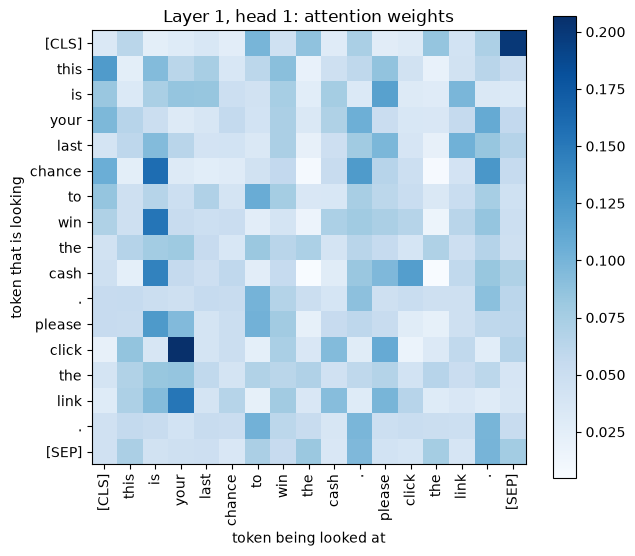

In [42]:
import math

layer1 = model.bert.encoder.layer[0].attention.self   # layer 1's attention: holds the real Wq, Wk, Wv
x = by_bert                                           # input = the embeddings from 13.2, shape (1, 17, 768)
n_heads, head_size = 12, 64

with torch.no_grad():
    # Step 1: Q, K, V for every token (768 numbers each)
    Q, K, V = layer1.query(x), layer1.key(x), layer1.value(x)

    # Step 2: split into 12 heads of 64 numbers: (1, 17, 768) → (1, 12, 17, 64)
    def split(t):
        return t.view(1, -1, n_heads, head_size).transpose(1, 2)
    Qh, Kh, Vh = split(Q), split(K), split(V)

    # Step 3: scores = Q · Kᵀ / √64, for every pair of tokens
    scores = Qh @ Kh.transpose(-2, -1) / math.sqrt(head_size)    # (1, 12, 17, 17)

    # Step 4: softmax → attention weights (each row adds up to 1)
    weights = torch.softmax(scores, dim=-1)

    # Step 5: mix the values, then glue the 12 heads back together
    context = (weights @ Vh).transpose(1, 2).reshape(1, -1, 768)  # (1, 17, 768)

print("Q, K, V shape:        ", tuple(Q.shape))
print("Per head:             ", tuple(Qh.shape), "→ (1 message, 12 heads, 17 tokens, 64 numbers)")
print("Attention weights:    ", tuple(weights.shape), "→ 12 heads × 17 tokens × 17 tokens")

# --- Check against BERT's own calculation ---
captured = {}
def grab(module, inputs, output):
    captured["out"] = output[0] if isinstance(output, tuple) else output
hook = layer1.register_forward_hook(grab)
with torch.no_grad():
    model.bert(input_ids=ids, attention_mask=enc["attention_mask"].to(device))
hook.remove()
print("\nDoes our attention match BERT's own?", torch.allclose(context, captured["out"], atol=1e-4))

# --- Where does 'win' look, in head 1? ---
head = 0
i = tokens.index("win")
print(f"\nIn head {head + 1}, the token 'win' pays attention to:")
row = weights[0, head, i].cpu()
for j in row.argsort(descending=True)[:5].tolist():
    print(f"  {tokens[j]:8s} {row[j].item():6.1%}")
print(f"  (all 17 percentages add up to {row.sum().item():.0%})")

# --- Picture of head 1 ---
plt.figure(figsize=(7, 6))
plt.imshow(weights[0, head].cpu(), cmap="Blues")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("token being looked at"); plt.ylabel("token that is looking")
plt.title(f"Layer 1, head {head + 1}: attention weights")
plt.colorbar(); plt.show()

In [43]:
row = weights[0, head, tokens.index("win")].cpu()
for pos, (token, w) in enumerate(zip(tokens, row.tolist())):
    print(f"position {pos:2d} | {token:8s} | {w:6.1%}")
print(f"\nTotal: {row.sum().item():.1%}")

position  0 | [CLS]    |   7.0%
position  1 | this     |   4.7%
position  2 | is       |  15.3%
position  3 | your     |   5.2%
position  4 | last     |   4.8%
position  5 | chance   |   5.1%
position  6 | to       |   2.6%
position  7 | win      |   3.9%
position  8 | the      |   1.6%
position  9 | cash     |   7.1%
position 10 | .        |   7.8%
position 11 | please   |   7.2%
position 12 | click    |   6.5%
position 13 | the      |   1.6%
position 14 | link     |   6.3%
position 15 | .        |   8.5%
position 16 | [SEP]    |   4.9%

Total: 100.0%


### 13.4 Through all 12 layers: the final [CLS] vector

Number of stages: 13 (1 embedding step + 12 layers)
Shape at each stage: (1, 17, 768) → (1 message, 17 tokens, 768 numbers)
Stage 0 matches our embeddings from 13.2? True

Final [CLS] vector shape: (768,)
First 5 of its 768 numbers: [ 0.117 -0.372  0.311  0.19   0.861]


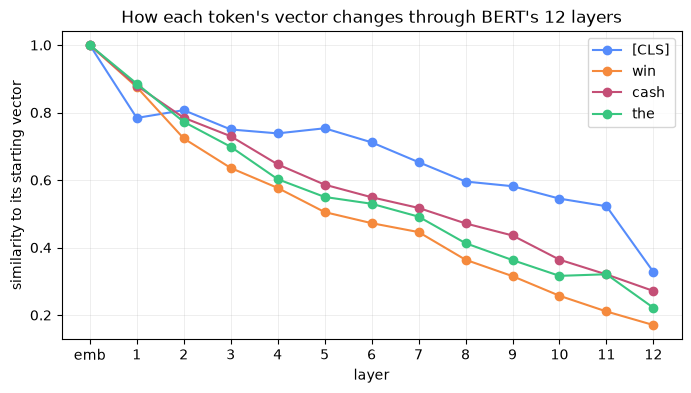

In [44]:
import torch.nn.functional as F

with torch.no_grad():
    out = model.bert(input_ids=ids,
                     attention_mask=enc["attention_mask"].to(device),
                     output_hidden_states=True)          # keep the result of every layer

hidden = out.hidden_states    # 13 stages: the embeddings + after each of the 12 layers
print("Number of stages:", len(hidden), "(1 embedding step + 12 layers)")
print("Shape at each stage:", tuple(hidden[0].shape), "→ (1 message, 17 tokens, 768 numbers)")
print("Stage 0 matches our embeddings from 13.2?", torch.allclose(hidden[0], by_bert, atol=1e-5))

cls_final = out.last_hidden_state[0, 0]                 # position 0 = [CLS], after layer 12
print("\nFinal [CLS] vector shape:", tuple(cls_final.shape))
print("First 5 of its 768 numbers:", cls_final[:5].cpu().numpy().round(3))

# How much does each token's vector change, layer by layer?
watch = ["[CLS]", "win", "cash", "the"]
plt.figure(figsize=(8, 4))
for t in watch:
    i = tokens.index(t)
    start = hidden[0][0, i]
    similarity = [F.cosine_similarity(start, h[0, i], dim=0).item() for h in hidden]
    plt.plot(range(13), similarity, marker="o", label=t)
plt.xticks(range(13), ["emb"] + [str(layer) for layer in range(1, 13)])
plt.xlabel("layer"); plt.ylabel("similarity to its starting vector")
plt.title("How each token's vector changes through BERT's 12 layers")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [45]:
rows = []
for t in watch:
    i = tokens.index(t)
    start = hidden[0][0, i]
    rows.append([F.cosine_similarity(start, h[0, i], dim=0).item() for h in hidden])

table = pd.DataFrame(rows, index=watch, columns=["emb"] + [f"L{layer}" for layer in range(1, 13)])
table.round(3)

,emb,L1,L2,L3,L4,L5,L6,L7,L8,L9,L10,L11,L12
[CLS],1.0,0.784,0.807,0.750,0.738,0.753,0.712,0.653,0.596,0.582,0.545,0.522,0.328
win,1.0,0.875,0.723,0.636,0.577,0.505,0.472,0.446,0.364,0.315,0.257,0.211,0.170
cash,1.0,0.880,0.785,0.730,0.647,0.586,0.549,0.517,0.472,0.436,0.364,0.320,0.271
the,1.0,0.886,0.772,0.699,0.603,0.550,0.530,0.492,0.413,0.363,0.316,0.321,0.222


### 13.5 From the [CLS] vector to the spam probability, calculated step by step

In [46]:
lin1, relu, drop, lin2 = model.classifier    # the 4 classifier layers from section 8

with torch.no_grad():
    # Step 1: Linear 768 → 256: weights × [CLS] vector + bias
    h = lin1.weight @ cls_final + lin1.bias
    print("After Linear 1:", tuple(h.shape), "| first 5:", h[:5].cpu().numpy().round(3))

    # Step 2: ReLU: negative numbers become 0
    h_relu = torch.clamp(h, min=0)
    active = int((h_relu > 0).sum())
    print(f"After ReLU: {active} of 256 neurons are positive, {256 - active} became 0")

    # Step 3: Dropout is switched off when checking (model.eval()), so nothing changes here

    # Step 4: Linear 256 → 1: one final score
    score = (lin2.weight @ h_relu + lin2.bias).item()
    print(f"\nFinal score: {score:.3f}")

    # Step 5: sigmoid: score → spam probability
    probability = 1 / (1 + math.exp(-score))
    print(f"Sigmoid: 1 / (1 + e^(-{score:.3f})) = {probability:.1%}")

    # Check: does our result match the model's own calculation?
    model_score = model(ids, enc["attention_mask"].to(device)).item()
    model_probability = torch.sigmoid(torch.tensor(model_score)).item()
    print(f"\nModel's own result: score {model_score:.3f} → {model_probability:.1%}")
    print("Do they match?", abs(probability - model_probability) < 1e-4)

After Linear 1: (256,) | first 5: [-1.349 -0.539  2.276 -1.08  -0.012]
After ReLU: 81 of 256 neurons are positive, 175 became 0

Final score: 1.619
Sigmoid: 1 / (1 + e^(-1.619)) = 83.5%

Model's own result: score 1.619 → 83.5%
Do they match? True


## 14. Save the key numbers for the interactive walkthrough

In [49]:
import json, os, math
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def to_list(t, decimals=4):
    return np.round(t.detach().float().cpu().numpy().astype(float), decimals).tolist()

def spam_probability(text):
    e = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
    with torch.no_grad():
        return torch.sigmoid(model(e["input_ids"].to(device), e["attention_mask"].to(device))).item()

model.eval()
example = "This is your last chance to WIN the CASH. Please click the link."
enc = tokenizer(example, return_tensors="pt")
ids = enc["input_ids"].to(device)
att_mask = enc["attention_mask"].to(device)
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
n = len(tokens)

with torch.no_grad():
    # --- Embeddings: the three table rows, their sum, and the normalization ---
    emb = model.bert.embeddings
    pos_ids   = torch.arange(n, device=device).unsqueeze(0)
    word_part = emb.word_embeddings(ids)[0]
    pos_part  = emb.position_embeddings(pos_ids)[0]
    seg_part  = emb.token_type_embeddings(torch.zeros_like(ids))[0]
    summed    = word_part + pos_part + seg_part
    mean      = summed.mean(dim=-1)
    spread    = torch.sqrt(summed.var(dim=-1, unbiased=False) + emb.LayerNorm.eps)
    normalized = emb.LayerNorm(summed)

    # --- All 12 layers: inputs and outputs ---
    out = model.bert(input_ids=ids, attention_mask=att_mask, output_hidden_states=True)
    hidden = out.hidden_states

    # --- Attention for all 12 layers × 12 heads ---
    layers = []
    for L in range(12):
        att = model.bert.encoder.layer[L].attention.self
        x = hidden[L]                                             # the input to this layer
        split = lambda t: t.view(1, n, 12, 64).transpose(1, 2)[0] # (12 heads, tokens, 64)
        Q, K, V = split(att.query(x)), split(att.key(x)), split(att.value(x))
        scores = Q @ K.transpose(-2, -1) / math.sqrt(64)          # before softmax
        weights = torch.softmax(scores, dim=-1)                   # after softmax
        layers.append({"q_first_8": to_list(Q[:, :, :8], 3), "k_first_8": to_list(K[:, :, :8], 3),
                       "v_first_8": to_list(V[:, :, :8], 3),
                       "scores": to_list(scores, 3), "weights": to_list(weights, 4)})

    similarity = [[F.cosine_similarity(hidden[0][0, i], hs[0, i], dim=0).item() for hs in hidden]
                  for i in range(n)]

    # --- Classifier ---
    cls = out.last_hidden_state[0, 0]
    lin1, _, _, lin2 = model.classifier
    h1 = lin1(cls)
    h1_relu = torch.relu(h1)
    final_score = lin2(h1_relu).item()
    final_probability = torch.sigmoid(torch.tensor(final_score)).item()

my_examples = [
    "This is your last chance to WIN the CASH. Please click the link.",
    "Dear Vamshi, I hope to see you on Sunday.",
    "I won the office quiz competition yesterday, the prize was a free dinner haha",
]

try:
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    test_results = {"accuracy": accuracy_score(y_true, y_pred), "spam_precision": precision,
                    "spam_recall": recall, "spam_f1": f1,
                    "confusion_matrix": {"true_negatives": int(tn), "false_positives": int(fp),
                                         "false_negatives": int(fn), "true_positives": int(tp)}}
except NameError:
    test_results = None
    print("Note: run section 11.4 first to include the test results")

walkthrough = {
    "project": "Hugging Face: SPAM Classification Using BERT",
    "message": example,
    "tokens": tokens,
    "token_ids": enc["input_ids"][0].tolist(),
    "embeddings": {
        "word_first_8": to_list(word_part[:, :8]),
        "position_first_8": to_list(pos_part[:, :8]),
        "segment_first_8": to_list(seg_part[:, :8]),
        "sum_first_8": to_list(summed[:, :8]),
        "mean_of_768": to_list(mean, 6),
        "spread_of_768": to_list(spread, 6),
        "layernorm_scale_first_8": to_list(emb.LayerNorm.weight[:8]),
        "layernorm_shift_first_8": to_list(emb.LayerNorm.bias[:8]),
        "normalized_first_8": to_list(normalized[:, :8]),
    },
    "attention_layers": layers,
    "similarity_to_start_per_layer": np.round(similarity, 4).tolist(),
    "classifier": {
        "cls_768": to_list(cls),
        "linear1_weights_first_8_neurons": to_list(lin1.weight[:8]),
        "linear1_bias_first_8": to_list(lin1.bias[:8]),
        "after_linear1_256": to_list(h1),
        "linear2_weights_256": to_list(lin2.weight[0]),
        "linear2_bias": round(lin2.bias.item(), 4),
        "final_score": round(final_score, 4),
        "spam_probability": round(final_probability, 4),
    },
    "my_examples": [{"text": t, "spam_probability": round(spam_probability(t), 4)} for t in my_examples],
    "training_history": {k: [round(float(v), 4) for v in vals] for k, vals in history.items()},
    "test_results": test_results,
    "credits": {
        "dataset": "SMS Spam Collection by Tiago A. Almeida and José María Gómez Hidalgo, "
                   "UCI Machine Learning Repository, CC BY 4.0",
        "model": "BERT (bert-base-uncased) by Google, Apache 2.0",
    },
}

with open("bert_walkthrough_data.json", "w", encoding="utf-8") as f:
    json.dump(walkthrough, f, ensure_ascii=False, separators=(",", ":"))

print("Saved bert_walkthrough_data.json:", round(os.path.getsize("bert_walkthrough_data.json") / 1024), "KB")

Saved bert_walkthrough_data.json: 986 KB


## 15. Summary

**Goal:** Classify SMS messages as spam or ham (not spam) by fine-tuning Google's pre-trained BERT model.

**What I did:**
- Loaded the SMS Spam Collection, removed 403 duplicates (5,171 messages left, 12.63% spam) and split it 70/15/15 with the same spam share in each part.
- Tokenized the messages with the `bert-base-uncased` tokenizer (maximum length 128).
- Added a small classifier on top of BERT (768 → 256 → ReLU → Dropout → 1) and fine-tuned the whole model for 3 epochs.
- Kept the epoch with the lowest validation loss (epoch 1) to avoid overfitting.
- Looked inside the model step by step: tokens, embeddings, attention, the 12 layers and the classifier.

**Results on the test set (776 messages):**

| Metric | Value |
|---|---|
| Accuracy | 99.36% |
| Spam precision | 100% (no real message was flagged as spam) |
| Spam recall | 94.9% (5 of 98 spam messages were missed) |
| Spam F1 score | 0.974 |

**What I learned:**
- How a pre-trained model can be adapted to a new task with relatively little data.
- How BERT turns text into numbers, and how attention lets each word take information from the others.
- Why accuracy alone isn't enough for imbalanced data, and why precision matters most for a spam filter.